# Exercise 2: Convolutional Neural Network on CIFAR-10

**Aim.** Replace the Exercise 1 MLP with a CNN containing exactly three trainable convolutional layers, and compare the two models on classification accuracy, training and validation loss, and parameter count.

**Controlled comparison.** The CNN uses the same seeded 45,000/5,000 train/validation split, the same normalisation statistics, batch size (`128`), loss (cross-entropy), 30-epoch budget, and lowest-validation-loss checkpointing as Exercise 1. The optimiser is chosen with **the same procedure and the same three candidates as Exercise 1** (10 epochs each, lowest validation loss wins), so each model is trained with the optimiser that suits it best, chosen without touching the test set. The original 10,000-image test partition is used only for final evaluation.

**How to run.** Run `Exercise 1 MLP.ipynb` first (it saves the shared configuration), install `requirements.txt`, start Jupyter, and use **Kernel > Restart Kernel and Run All**. On a laptop GPU this notebook takes about 5 minutes.

## 1. Setup: imports, reproducibility, and paths

In [1]:
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
for directory in (DATA_DIR, OUTPUT_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

CONFIG_PATH = OUTPUT_DIR / "exercise1 config.json"
MLP_METRICS_PATH = OUTPUT_DIR / "exercise1 metrics.json"
MLP_HISTORY_PATH = OUTPUT_DIR / "exercise1 history.csv"
for required_path in (CONFIG_PATH, MLP_METRICS_PATH, MLP_HISTORY_PATH):
    if not required_path.exists():
        raise FileNotFoundError(f"'{required_path}' not found. Run 'Exercise 1 MLP.ipynb' first.")

with CONFIG_PATH.open("r") as config_file:
    exercise1_config = json.load(config_file)

SEED = exercise1_config["seed"]
BATCH_SIZE = exercise1_config["batch_size"]
EPOCHS = exercise1_config["epochs"]
SELECTION_EPOCHS = exercise1_config["optimiser_selection_epochs"]
CHANNEL_MEAN = exercise1_config["normalisation"]["mean"]
CHANNEL_STD = exercise1_config["normalisation"]["std"]
VAL_INDICES = exercise1_config["validation_indices"]


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch {torch.__version__} | device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Seed: {SEED} | Batch size: {BATCH_SIZE} | Epochs: {EPOCHS} | Selection epochs: {SELECTION_EPOCHS}")
print(f"Exercise 1 (MLP) selected optimiser: {exercise1_config['optimiser']['name']}")

PyTorch 2.14.0+cu126 | device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Seed: 42 | Batch size: 128 | Epochs: 30 | Selection epochs: 10
Exercise 1 (MLP) selected optimiser: SGD lr=0.01 momentum=0.9


## 2. Dataset split and preprocessing

CIFAR-10 contains 50,000 training images and 10,000 test images. Exercise 1 saved the indices of its seeded 5,000-image validation split; the same indices are reused here, so the CNN and MLP see exactly the same training, validation and test images. The channel means and standard deviations (computed on the training split only) are also reused.

The images are converted to normalised tensors once and kept in memory (`TensorDataset`). This is faster than re-decoding images every epoch, and it is the same pipeline that Exercise 3 uses, so the Exercise 3 baseline reproduces this notebook's CNN exactly. A seeded `torch.Generator` fixes the mini-batch order.

In [2]:
try:
    raw_train_dataset = datasets.CIFAR10(DATA_DIR, train=True, download=True)
    raw_test_dataset = datasets.CIFAR10(DATA_DIR, train=False, download=True)
except Exception as error:
    raise RuntimeError(f"Could not download or load CIFAR-10 in '{DATA_DIR}'.") from error

CLASS_NAMES = raw_train_dataset.classes
val_index_set = set(VAL_INDICES)
TRAIN_INDICES = [idx for idx in range(len(raw_train_dataset)) if idx not in val_index_set]

mean_tensor = torch.tensor(CHANNEL_MEAN, dtype=torch.float32).view(1, 3, 1, 1)
std_tensor = torch.tensor(CHANNEL_STD, dtype=torch.float32).view(1, 3, 1, 1)


def prepare_normalised_tensors(images_np, targets_list, indices=None):
    """Convert uint8 HWC images to normalised float CHW tensors."""
    if indices is not None:
        images_np = images_np[indices]
        targets_list = [targets_list[i] for i in indices]
    x = torch.from_numpy(images_np).permute(0, 3, 1, 2).float().div_(255.0)
    x = (x - mean_tensor) / std_tensor
    y = torch.tensor(targets_list, dtype=torch.long)
    return x, y


X_train, y_train = prepare_normalised_tensors(raw_train_dataset.data, raw_train_dataset.targets, TRAIN_INDICES)
X_val, y_val = prepare_normalised_tensors(raw_train_dataset.data, raw_train_dataset.targets, VAL_INDICES)
X_test, y_test = prepare_normalised_tensors(raw_test_dataset.data, raw_test_dataset.targets)

train_tensor_dataset = TensorDataset(X_train, y_train)


def make_train_loader(seed=SEED):
    # A seeded generator gives every training run the same mini-batch order.
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(train_tensor_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generator)


train_eval_loader = DataLoader(train_tensor_dataset, batch_size=BATCH_SIZE, shuffle=False)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

print(f"Training images:   {len(X_train):,}")
print(f"Validation images: {len(X_val):,}")
print(f"Test images:       {len(X_test):,}")
print(f"Overlap between train and val indices: {len(set(TRAIN_INDICES) & val_index_set)}")

Training images:   45,000
Validation images: 5,000
Test images:       10,000
Overlap between train and val indices: 0


## 3. CNN architecture

The model has exactly three trainable layers, all convolutional:

1. `Conv2d(3, 32, 3, padding=1)` → `ReLU` → `MaxPool2d(2)`: learns 32 local RGB patterns (edges, colour blobs); output $32 \times 16 \times 16$.
2. `Conv2d(32, 64, 3, padding=1)` → `ReLU` → `MaxPool2d(2)`: combines first-layer maps into 64 textures and parts; output $64 \times 8 \times 8$.
3. `Conv2d(64, 10, 3, padding=1)` → `AdaptiveAvgPool2d(1)`: produces one $8 \times 8$ evidence map per class; global average pooling turns each map into one class logit.

Using global average pooling instead of a fully connected head keeps the model at three trainable layers and very few parameters, and makes each output channel directly interpretable as a class score map.

**No activation after the last layer.** The pooled outputs of layer 3 are the class logits that go into cross-entropy, so they must be free to take negative values. An earlier version applied a `ReLU` here, which forced every logit to be $\geq 0$: the network could not push wrong classes below zero, and a class map that became entirely negative stopped receiving gradient. Removing it changes no parameters but substantially improves learning.

In [3]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            # No ReLU here: the pooled outputs of this layer are the class logits,
            # which must be able to take negative values.
            nn.Conv2d(64, 10, kernel_size=3, padding=1),
            nn.AdaptiveAvgPool2d((1, 1)),
        )

    def forward(self, images):
        return self.features(images).flatten(1)


def count_trainable_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


model = CNN().to(DEVICE)
PARAMETER_COUNT = count_trainable_parameters(model)
print(model)
for name, parameter in model.named_parameters():
    print(f"{name:20s} {str(tuple(parameter.shape)):18s} {parameter.numel():>7,}")
print(f"Trainable parameters: {PARAMETER_COUNT:,}")

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): AdaptiveAvgPool2d(output_size=(1, 1))
  )
)
features.0.weight    (32, 3, 3, 3)          864
features.0.bias      (32,)                   32
features.3.weight    (64, 32, 3, 3)      18,432
features.3.bias      (64,)                   64
features.6.weight    (10, 64, 3, 3)       5,760
features.6.bias      (10,)                   10
Trainable parameters: 25,162


## 4. Training and evaluation functions

Cross-entropy is used for ten mutually exclusive classes. Epoch losses are weighted by batch size so they are true means over all samples. `train_model` saves a checkpoint whenever validation loss improves (marked `*`), so the final evaluation uses the lowest-validation-loss epoch. The test set is evaluated only once, after the main run.

In [4]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_samples += labels.size(0)
    return total_loss / total_samples, 100 * total_correct / total_samples


def evaluate(model, loader, criterion):
    model.eval()
    total_loss, total_samples = 0.0, 0
    all_predictions, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            logits = model(images)
            total_loss += criterion(logits, labels).item() * labels.size(0)
            total_samples += labels.size(0)
            all_predictions.append(logits.argmax(dim=1).cpu())
            all_labels.append(labels.cpu())
    predictions = torch.cat(all_predictions).numpy()
    labels = torch.cat(all_labels).numpy()
    accuracy = 100 * (predictions == labels).mean()
    return total_loss / total_samples, accuracy, predictions, labels


def train_model(model, optimizer, criterion, epochs, run_name, checkpoint_path=None, print_every=1):
    train_loader = make_train_loader(SEED)
    history = []
    best_val_loss = float("inf")
    best_epoch = 0
    for epoch in range(1, epochs + 1):
        epoch_start = time.perf_counter()
        train_loss, train_accuracy = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_accuracy, _, _ = evaluate(model, val_loader, criterion)
        epoch_seconds = time.perf_counter() - epoch_start
        improved = val_loss < best_val_loss
        if improved:
            best_val_loss = val_loss
            best_epoch = epoch
            if checkpoint_path is not None:
                torch.save(model.state_dict(), checkpoint_path)
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "epoch_seconds": epoch_seconds,
        })
        if epoch == 1 or epoch % print_every == 0 or epoch == epochs:
            print(f"[{run_name}] epoch {epoch:2d}/{epochs} | train loss {train_loss:.4f} acc {train_accuracy:5.2f}% | "
                  f"val loss {val_loss:.4f} acc {val_accuracy:5.2f}% | {epoch_seconds:4.1f}s"
                  f"{' *' if improved else ''}")
    return pd.DataFrame(history), best_epoch

## 5. Optimiser selection on validation

Exercise 1 compared three optimiser settings for the MLP and chose the one with the lowest validation loss after 10 epochs. The same three candidates and the same procedure are applied to the CNN, each starting from identical initial weights and the same batch order. Only the validation set is used; the test set plays no part in this choice. Re-using the procedure (rather than forcing the MLP's optimiser onto the CNN) keeps the comparison fair: a convolutional network with 68× fewer parameters can have a different best optimiser from a large fully connected one.

[Adam lr=1e-3] epoch  1/10 | train loss 1.8058 acc 33.53% | val loss 1.6233 acc 39.40% |  2.9s *


[Adam lr=1e-3] epoch  5/10 | train loss 1.3333 acc 52.55% | val loss 1.3680 acc 50.76% |  1.7s


[Adam lr=1e-3] epoch 10/10 | train loss 1.1753 acc 58.33% | val loss 1.1701 acc 59.12% |  1.7s *


[Adam lr=1e-4] epoch  1/10 | train loss 2.1095 acc 22.30% | val loss 1.9958 acc 26.14% |  1.8s *


[Adam lr=1e-4] epoch  5/10 | train loss 1.6956 acc 38.28% | val loss 1.6834 acc 40.28% |  2.4s *


[Adam lr=1e-4] epoch 10/10 | train loss 1.5877 acc 42.73% | val loss 1.5990 acc 42.74% |  3.8s *


[SGD lr=0.01 momentum=0.9] epoch  1/10 | train loss 1.9405 acc 27.50% | val loss 1.7304 acc 33.80% |  3.6s *


[SGD lr=0.01 momentum=0.9] epoch  5/10 | train loss 1.3647 acc 51.45% | val loss 1.4008 acc 49.48% |  3.0s *


[SGD lr=0.01 momentum=0.9] epoch 10/10 | train loss 1.1578 acc 59.40% | val loss 1.1543 acc 60.48% |  2.9s *

Chosen optimiser for the CNN: SGD lr=0.01 momentum=0.9


,best val loss,best epoch,val accuracy at best epoch (%)
optimiser,,,
Adam lr=1e-3,1.1701,10,59.12
Adam lr=1e-4,1.5990,10,42.74
SGD lr=0.01 momentum=0.9,1.1543,10,60.48


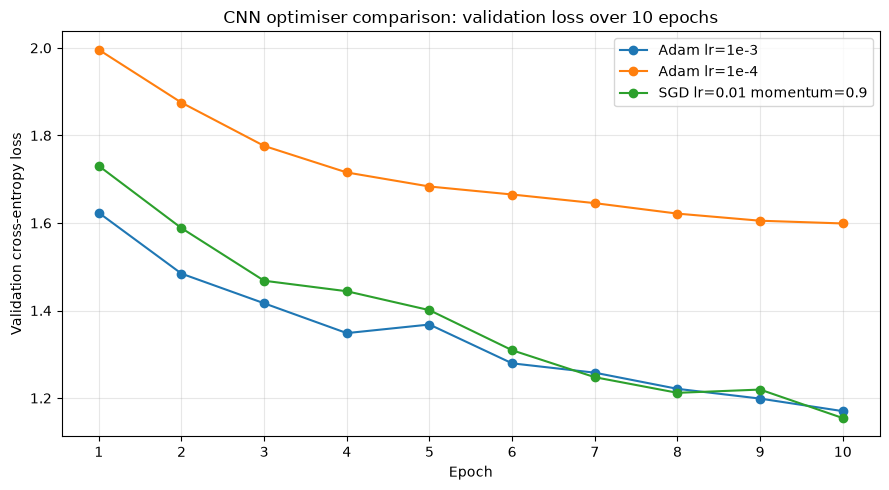

In [5]:
criterion = nn.CrossEntropyLoss()

OPTIMISER_CANDIDATES = {
    "Adam lr=1e-3": (torch.optim.Adam, {"lr": 1e-3}),
    "Adam lr=1e-4": (torch.optim.Adam, {"lr": 1e-4}),
    "SGD lr=0.01 momentum=0.9": (torch.optim.SGD, {"lr": 0.01, "momentum": 0.9}),
}

selection_histories = {}
for candidate_name, (optimiser_class, optimiser_settings) in OPTIMISER_CANDIDATES.items():
    set_seed(SEED)
    candidate_model = CNN().to(DEVICE)
    candidate_optimiser = optimiser_class(candidate_model.parameters(), **optimiser_settings)
    selection_histories[candidate_name], _ = train_model(
        candidate_model, candidate_optimiser, criterion, SELECTION_EPOCHS, candidate_name, print_every=5
    )

selection_summary = pd.DataFrame([
    {
        "optimiser": candidate_name,
        "best val loss": history["val_loss"].min(),
        "best epoch": int(history.loc[history["val_loss"].idxmin(), "epoch"]),
        "val accuracy at best epoch (%)": history.loc[history["val_loss"].idxmin(), "val_accuracy"],
    }
    for candidate_name, history in selection_histories.items()
]).set_index("optimiser")

CHOSEN_OPTIMISER = selection_summary["best val loss"].idxmin()
CHOSEN_OPTIMISER_CLASS, CHOSEN_OPTIMISER_SETTINGS = OPTIMISER_CANDIDATES[CHOSEN_OPTIMISER]
print(f"\nChosen optimiser for the CNN: {CHOSEN_OPTIMISER}")
display(selection_summary.round(4))

figure, axis = plt.subplots(figsize=(9, 5))
for candidate_name, history in selection_histories.items():
    axis.plot(history["epoch"], history["val_loss"], marker="o", label=candidate_name)
axis.set(title=f"CNN optimiser comparison: validation loss over {SELECTION_EPOCHS} epochs",
         xlabel="Epoch", ylabel="Validation cross-entropy loss")
axis.set_xticks(range(1, SELECTION_EPOCHS + 1))
axis.grid(alpha=0.3)
axis.legend()
figure.tight_layout()
figure.savefig(FIGURE_DIR / "exercise2 optimiser comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# Save the CNN configuration so Exercise 3 can train its baseline identically.
exercise2_config = {
    "architecture": "Conv(3,32,3)-ReLU-MaxPool -> Conv(32,64,3)-ReLU-MaxPool -> Conv(64,10,3) -> GlobalAvgPool",
    "optimiser": {
        "name": CHOSEN_OPTIMISER,
        "class": CHOSEN_OPTIMISER_CLASS.__name__,
        "settings": CHOSEN_OPTIMISER_SETTINGS,
    },
}
with (OUTPUT_DIR / "exercise2 config.json").open("w") as config_file:
    json.dump(exercise2_config, config_file, indent=2)

## 6. Main training run

A fresh CNN is trained for 30 epochs with the selected optimiser, starting from the same seeded initialisation and batch order.

In [6]:
set_seed(SEED)
model = CNN().to(DEVICE)
optimizer = CHOSEN_OPTIMISER_CLASS(model.parameters(), **CHOSEN_OPTIMISER_SETTINGS)
CHECKPOINT_PATH = OUTPUT_DIR / "exercise2 best model.pt"
HISTORY_PATH = OUTPUT_DIR / "exercise2 history.csv"

history, best_epoch = train_model(model, optimizer, criterion, EPOCHS, "main", checkpoint_path=CHECKPOINT_PATH)
TOTAL_TRAINING_SECONDS = float(history["epoch_seconds"].sum())
history.to_csv(HISTORY_PATH, index=False)
model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True))

print(f"Best validation epoch: {best_epoch} | total training time: {TOTAL_TRAINING_SECONDS:.0f}s")

[main] epoch  1/30 | train loss 1.9405 acc 27.50% | val loss 1.7304 acc 33.80% |  3.2s *


[main] epoch  2/30 | train loss 1.6481 acc 39.54% | val loss 1.5883 acc 42.76% |  4.2s *


[main] epoch  3/30 | train loss 1.5193 acc 44.97% | val loss 1.4681 acc 47.98% |  3.9s *


[main] epoch  4/30 | train loss 1.4335 acc 48.37% | val loss 1.4441 acc 48.86% |  2.8s *


[main] epoch  5/30 | train loss 1.3647 acc 51.45% | val loss 1.4008 acc 49.48% |  5.3s *


[main] epoch  6/30 | train loss 1.3097 acc 53.42% | val loss 1.3093 acc 54.12% |  4.9s *


... (20 outputs left out)

[main] epoch 27/30 | train loss 0.8938 acc 68.94% | val loss 0.9303 acc 67.72% |  3.7s *


[main] epoch 28/30 | train loss 0.8921 acc 68.81% | val loss 0.9478 acc 67.50% |  3.1s


[main] epoch 29/30 | train loss 0.8746 acc 69.76% | val loss 0.9219 acc 68.22% |  3.7s *


[main] epoch 30/30 | train loss 0.8719 acc 69.53% | val loss 0.9777 acc 65.82% |  3.3s
Best validation epoch: 29 | total training time: 123s


## 7. Final train, validation, and test evaluation

In [7]:
train_loss, train_accuracy, _, _ = evaluate(model, train_eval_loader, criterion)
val_loss, val_accuracy, _, _ = evaluate(model, val_loader, criterion)
test_loss, test_accuracy, test_predictions, test_labels = evaluate(model, test_loader, criterion)

test_matrix = confusion_matrix(test_labels, test_predictions)
per_class_accuracy = 100 * test_matrix.diagonal() / test_matrix.sum(axis=1)

metrics = {
    "train": {"loss": float(train_loss), "accuracy": float(train_accuracy)},
    "validation": {"loss": float(val_loss), "accuracy": float(val_accuracy)},
    "test": {"loss": float(test_loss), "accuracy": float(test_accuracy)},
    "train_minus_test_accuracy_gap": float(train_accuracy - test_accuracy),
    "best_epoch": int(best_epoch),
    "parameter_count": int(PARAMETER_COUNT),
    "optimiser": CHOSEN_OPTIMISER,
    "total_training_seconds": TOTAL_TRAINING_SECONDS,
    "device": str(DEVICE),
    "per_class_test_accuracy": {name: float(acc) for name, acc in zip(CLASS_NAMES, per_class_accuracy)},
}

with (OUTPUT_DIR / "exercise2 metrics.json").open("w") as metrics_file:
    json.dump(metrics, metrics_file, indent=2)

print(classification_report(test_labels, test_predictions, target_names=CLASS_NAMES, digits=4))
display(pd.DataFrame([
    {"partition": "Training", "loss": train_loss, "accuracy (%)": train_accuracy},
    {"partition": "Validation", "loss": val_loss, "accuracy (%)": val_accuracy},
    {"partition": "Test", "loss": test_loss, "accuracy (%)": test_accuracy},
]).round(4))

              precision    recall  f1-score   support

    airplane     0.7527    0.6360    0.6894      1000
  automobile     0.9051    0.6770    0.7746      1000
        bird     0.6169    0.5250    0.5673      1000
         cat     0.4953    0.5320    0.5130      1000
        deer     0.6255    0.6630    0.6437      1000
         dog     0.5781    0.6330    0.6043      1000
        frog     0.7400    0.7230    0.7314      1000
       horse     0.6989    0.7660    0.7309      1000
        ship     0.7609    0.8210    0.7898      1000
       truck     0.7157    0.8410    0.7733      1000

    accuracy                         0.6817     10000
   macro avg     0.6889    0.6817    0.6818     10000
weighted avg     0.6889    0.6817    0.6818     10000



,partition,loss,accuracy (%)
0,Training,0.8500,70.5067
1,Validation,0.9219,68.2200
2,Test,0.9184,68.1700


## 8. Loss and accuracy curves

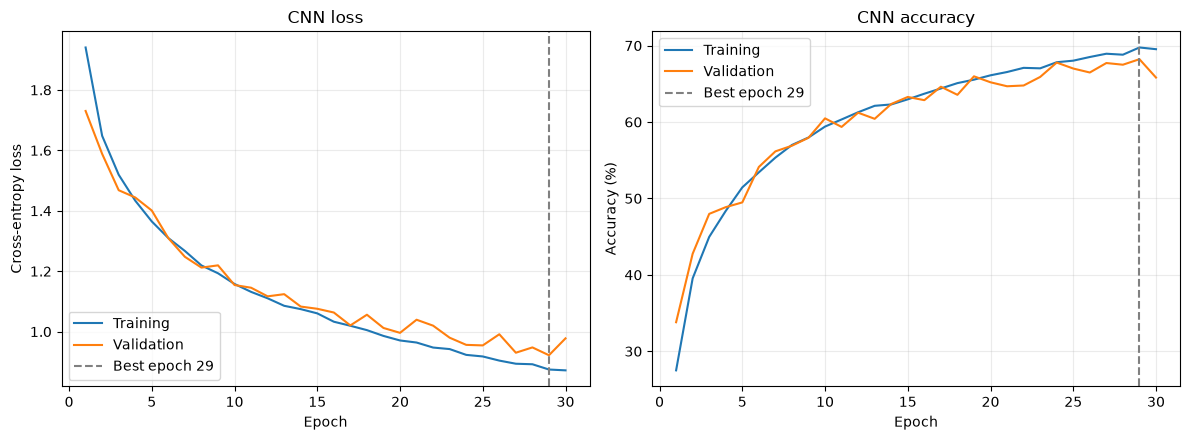

In [8]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(history["epoch"], history["train_loss"], label="Training")
axes[0].plot(history["epoch"], history["val_loss"], label="Validation")
axes[0].axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch {best_epoch}")
axes[0].set(title="CNN loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].plot(history["epoch"], history["train_accuracy"], label="Training")
axes[1].plot(history["epoch"], history["val_accuracy"], label="Validation")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch {best_epoch}")
axes[1].set(title="CNN accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
axes[1].grid(alpha=0.25)
axes[1].legend()
figure.tight_layout()
figure.savefig(FIGURE_DIR / "exercise2 training curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Test confusion matrix

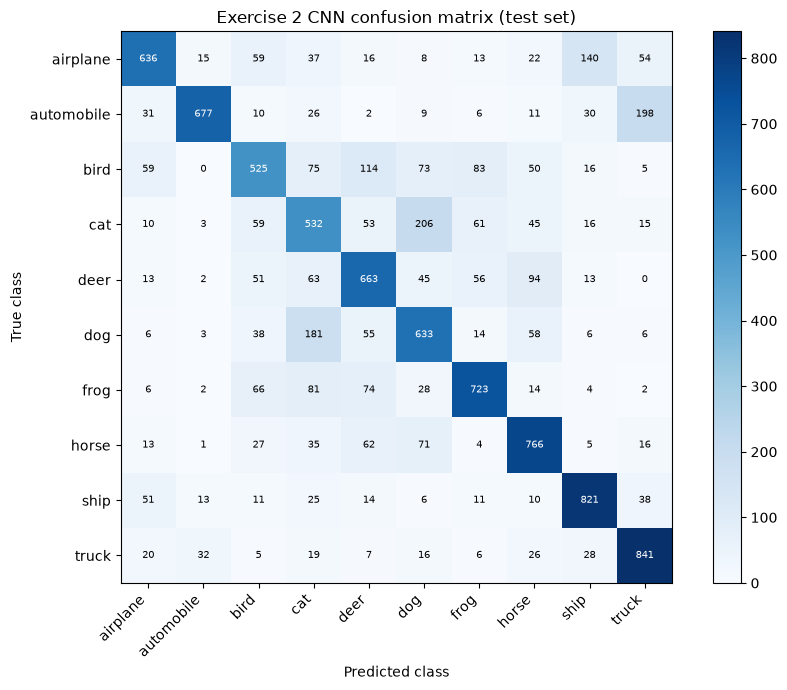

In [9]:
figure, axis = plt.subplots(figsize=(9, 7))
image = axis.imshow(test_matrix, cmap="Blues")
axis.set_xticks(range(10), CLASS_NAMES, rotation=45, ha="right")
axis.set_yticks(range(10), CLASS_NAMES)
axis.set_xlabel("Predicted class")
axis.set_ylabel("True class")
axis.set_title("Exercise 2 CNN confusion matrix (test set)")
for row in range(10):
    for column in range(10):
        axis.text(column, row, str(test_matrix[row, column]), ha="center", va="center", fontsize=7,
                  color="white" if test_matrix[row, column] > test_matrix.max() / 2 else "black")
figure.colorbar(image, ax=axis, fraction=0.046)
figure.tight_layout()
figure.savefig(FIGURE_DIR / "exercise2 confusion matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Direct MLP versus CNN comparison

The table combines Exercise 1's saved metrics with the CNN metrics: accuracy, training/validation/test loss, train–test gap, and trainable parameter count. The second figure overlays both models' training and validation loss curves, as required for the comparison.

Model,MLP (Exercise 1),CNN (Exercise 2)
Optimiser,SGD lr=0.01 momentum=0.9,SGD lr=0.01 momentum=0.9
Best epoch,6,29
Train accuracy (%),66.0489,70.5067
Validation accuracy (%),52.72,68.22
Test accuracy (%),53.64,68.17
Training loss,0.9778,0.85
Validation loss,1.3375,0.9219
Test loss,1.3466,0.9184
Train-test accuracy gap,12.4089,2.3367
Trainable parameters,1707274,25162


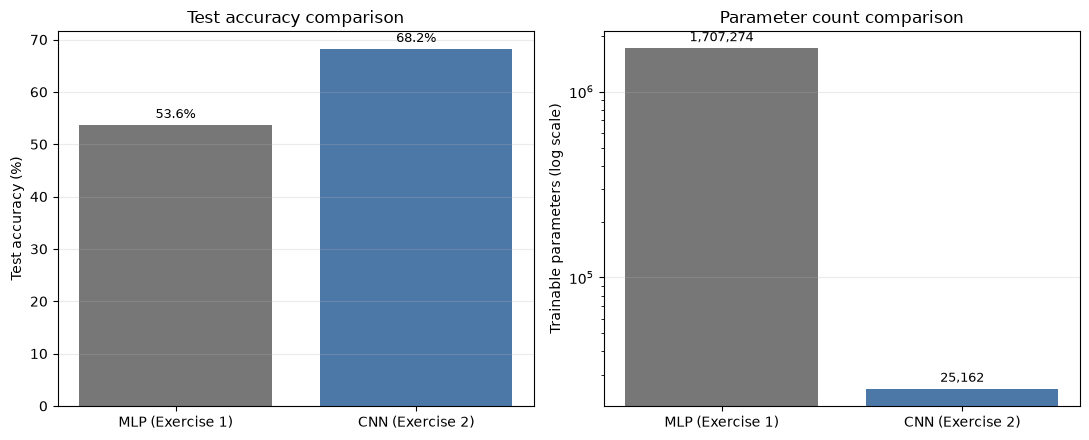

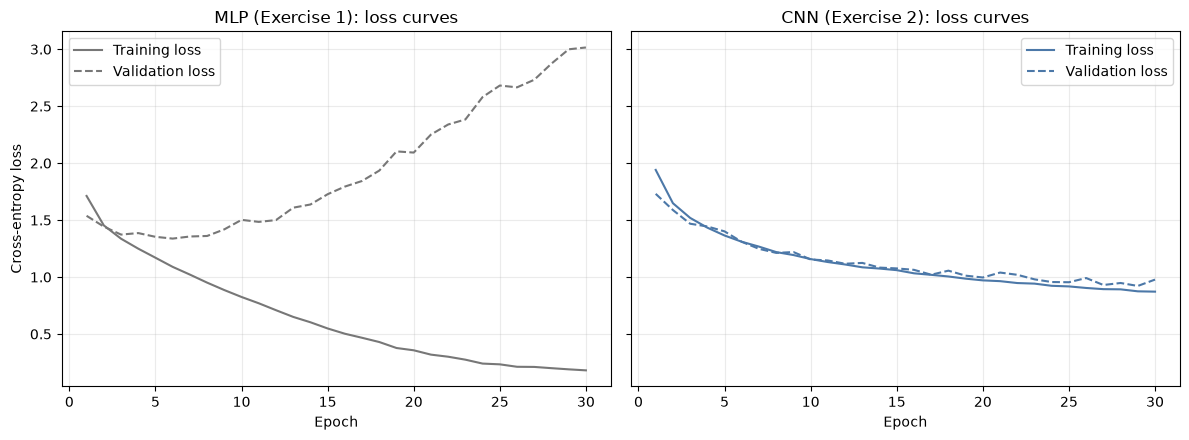

In [10]:
with MLP_METRICS_PATH.open("r") as metrics_file:
    mlp_metrics = json.load(metrics_file)
mlp_history = pd.read_csv(MLP_HISTORY_PATH)

comparison = pd.DataFrame([
    {
        "Model": "MLP (Exercise 1)",
        "Optimiser": mlp_metrics["chosen_optimiser"],
        "Best epoch": mlp_metrics["best_epoch"],
        "Train accuracy (%)": mlp_metrics["train"]["accuracy"],
        "Validation accuracy (%)": mlp_metrics["validation"]["accuracy"],
        "Test accuracy (%)": mlp_metrics["test"]["accuracy"],
        "Training loss": mlp_metrics["train"]["loss"],
        "Validation loss": mlp_metrics["validation"]["loss"],
        "Test loss": mlp_metrics["test"]["loss"],
        "Train-test accuracy gap": mlp_metrics["train_minus_test_accuracy_gap"],
        "Trainable parameters": mlp_metrics["parameter_count"],
    },
    {
        "Model": "CNN (Exercise 2)",
        "Optimiser": CHOSEN_OPTIMISER,
        "Best epoch": best_epoch,
        "Train accuracy (%)": train_accuracy,
        "Validation accuracy (%)": val_accuracy,
        "Test accuracy (%)": test_accuracy,
        "Training loss": train_loss,
        "Validation loss": val_loss,
        "Test loss": test_loss,
        "Train-test accuracy gap": train_accuracy - test_accuracy,
        "Trainable parameters": PARAMETER_COUNT,
    },
])
comparison.round(4).to_csv(OUTPUT_DIR / "exercise1 vs exercise2 comparison.csv", index=False)
display(comparison.round(4).set_index("Model").T)

colors = ["#777777", "#4c78a8"]
figure, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(comparison["Model"], comparison["Test accuracy (%)"], color=colors)
axes[0].set(ylabel="Test accuracy (%)", title="Test accuracy comparison")
axes[0].grid(axis="y", alpha=0.25)
axes[1].bar(comparison["Model"], comparison["Trainable parameters"], color=colors)
axes[1].set(ylabel="Trainable parameters (log scale)", title="Parameter count comparison", yscale="log")
axes[1].grid(axis="y", alpha=0.25)
for axis, column, fmt in ((axes[0], "Test accuracy (%)", "{:.1f}%"), (axes[1], "Trainable parameters", "{:,.0f}")):
    for index, value in enumerate(comparison[column]):
        axis.annotate(fmt.format(value), (index, value), ha="center", va="bottom", xytext=(0, 3),
                      textcoords="offset points", fontsize=9)
figure.tight_layout()
figure.savefig(FIGURE_DIR / "exercise1 vs exercise2 comparison.png", dpi=300, bbox_inches="tight")
plt.show()

figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for axis, (label, frame, color) in zip(axes, (("MLP (Exercise 1)", mlp_history, colors[0]),
                                              ("CNN (Exercise 2)", history, colors[1]))):
    axis.plot(frame["epoch"], frame["train_loss"], color=color, linestyle="-", label="Training loss")
    axis.plot(frame["epoch"], frame["val_loss"], color=color, linestyle="--", label="Validation loss")
    axis.set(title=f"{label}: loss curves", xlabel="Epoch")
    axis.grid(alpha=0.25)
    axis.legend()
axes[0].set_ylabel("Cross-entropy loss")
figure.tight_layout()
figure.savefig(FIGURE_DIR / "exercise1 vs exercise2 loss curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 11. Results and interpretation

### Summary of the comparison
| | MLP (Exercise 1) | CNN (Exercise 2) |
|---|---|---|
| Trainable layers | 3 fully connected | 3 convolutional |
| Trainable parameters | 1,707,274 | 25,162 (68× fewer) |
| Optimiser (selected on validation) | SGD, lr 0.01, momentum 0.9 | SGD, lr 0.01, momentum 0.9 |
| Best epoch (lowest validation loss) | 6 | 29 |
| Train / validation / test accuracy (%) | 66.05 / 52.72 / 53.64 | 70.51 / 68.22 / 68.17 |
| Train / validation / test loss | 0.978 / 1.338 / 1.347 | 0.850 / 0.922 / 0.918 |
| Train − test accuracy gap (points) | +12.4 | +2.3 |

Both models used the same data split, preprocessing, batch size, loss, epoch budget, checkpoint rule, and (after running the same selection procedure) the same optimiser, so the differences come from the architecture.

### Performance differences
- **Accuracy.** The CNN is 14.5 points more accurate on the test set (68.2% vs 53.6%) while using 1.5% of the MLP's parameters.
- **Loss curves and overfitting.** The MLP's validation loss reached its minimum at epoch 6 and then rose steeply (from 1.34 to 3.02 by epoch 30) while its training accuracy kept climbing to 93.8%: it memorised the training set. The CNN's training and validation losses fall together for almost the whole run, the best epoch is 29, and the final gap is only 2.3 points, so it is still learning general features when the budget ends.
- **Class-level errors.** Both models confuse the same visually similar pairs (cat/dog, automobile/truck, airplane/ship), but the CNN improves nine of the ten classes. The largest gains are on truck (+27.6 points), deer (+22.6), bird (+21.2), dog (+17.3) and cat (+15.9), classes where local shape and texture matter more than overall colour. The one exception is airplane (63.6% vs 67.5%): a likely reason is that airplanes usually sit on a large uniform sky, a global colour cue that the MLP can read directly from raw pixels, whereas the small CNN averages local evidence and has relatively few features for smooth, texture-less regions.

### How convolution influences feature learning
- **Local receptive fields.** Each 3×3 kernel looks at a small neighbourhood, so the first layer learns local patterns such as edges and colour transitions. The MLP connects every one of the 3,072 input values to every hidden unit and has no notion that neighbouring pixels are related; it must learn spatial structure from data alone.
- **Weight sharing and translation equivariance.** The same kernel slides over the whole image, so a feature detector learned in one position works everywhere. This is why the CNN needs so few parameters: layer 1 has 896 weights, against 1.57 million in the MLP's first layer. A cat's ear is detected wherever it appears, whereas the MLP would have to learn it separately for every position.
- **Hierarchy and pooling.** Max pooling halves the resolution after layers 1 and 2, so each output of layer 2 depends on an 8×8 pixel region of the original image and each output of layer 3 on an 18×18 region. Features become progressively more abstract (edges → textures → object parts), and pooling adds tolerance to small shifts. Global average pooling then averages class evidence over the whole image.
- **Inductive bias as regularisation.** These built-in assumptions match the structure of natural images, which acts as a strong prior: the CNN has far less capacity to memorise arbitrary pixel patterns, which explains its small train–test gap.

### Limitations
The CNN is small and capacity-limited (best epoch 29 of 30, train accuracy only 70.5%), so its accuracy is held back by model size rather than by overfitting. This motivates Exercise 3 (whether regularisation still helps such a model) and Exercise 4 (how width and depth change accuracy and overfitting). All results come from a single seed.